# Tarea 4 · Fritz renegocia, parte 4: la incertidumbre

**Curso:** Optimización metaheurística orientada a modelación hidrogeológica · UNAM, Instituto de Geología · noviembre de 2026
**Entrega:** a más tardar el viernes 27 de noviembre · **Tiempo estimado:** unas 2 horas · **Valor:** 10 puntos (8 automáticos, 2 de interpretación)

**Para aprobar:** este cuaderno se aprueba con **6 de 10** puntos. Con **2 de los 4 cuadernos** aprobados, el examen del curso está aprobado.

---

## El problema

Tres tareas creyéndole a un acuífero homogéneo. Fritz quiere saber qué decisión **resiste** a la geología y al clima que no conocemos, y **cuánta agua le
cuesta**. Es la ruta del cuaderno de la sesión 4, con los mismos datos para todos: pozos ≤ 3 m, humedal ≤ 1.25 m, tres pozos de 0 a 400 m³/d, demanda de
1 200 m³/d, 200 geologías para optimizar y otras 200 para validar. Las geologías las genera `hidra` con semillas fijas: son las mismas para todos y
las mismas del cuaderno de la sesión (`N_GEOLOGIAS = 200` en la celda de preparación; la tarea se entrega con 200).

| Etapa | Pregunta de Fritz |
|---|---|
| 1 | «Primero, la idea en una dimensión» (las dos cimas y la esperanza) |
| 2 | «¿Robusto según qué?» (medidas de robustez) |
| 3 | «¿Qué tan en serio tomo el frente de la sesión 3?» |
| 4 | «¿Cuánta agua, con qué riesgo?» (el frente exacto y OMOPSO robusto) |
| 5 | «¿Me puedo creer ese riesgo?» (validación y cuántas geologías) |
| 6 | «¿Y si además cambia el clima?» (el costo de la robustez) |
| 7 | «¿Vale la pena medir antes de decidir?» (una prueba de bombeo en el pozo 2) |
| 8 | «Explícamelo en palabras.» |

Igual que antes: escribe valores en los recuadros **INGRESA AQUÍ LOS DATOS SOLICITADOS**, ejecuta, y revisa con `grader.check`.
Todo lo que se pide está hecho en el cuaderno de la sesión 4 (`S4_robustez_rrwpt.ipynb`).

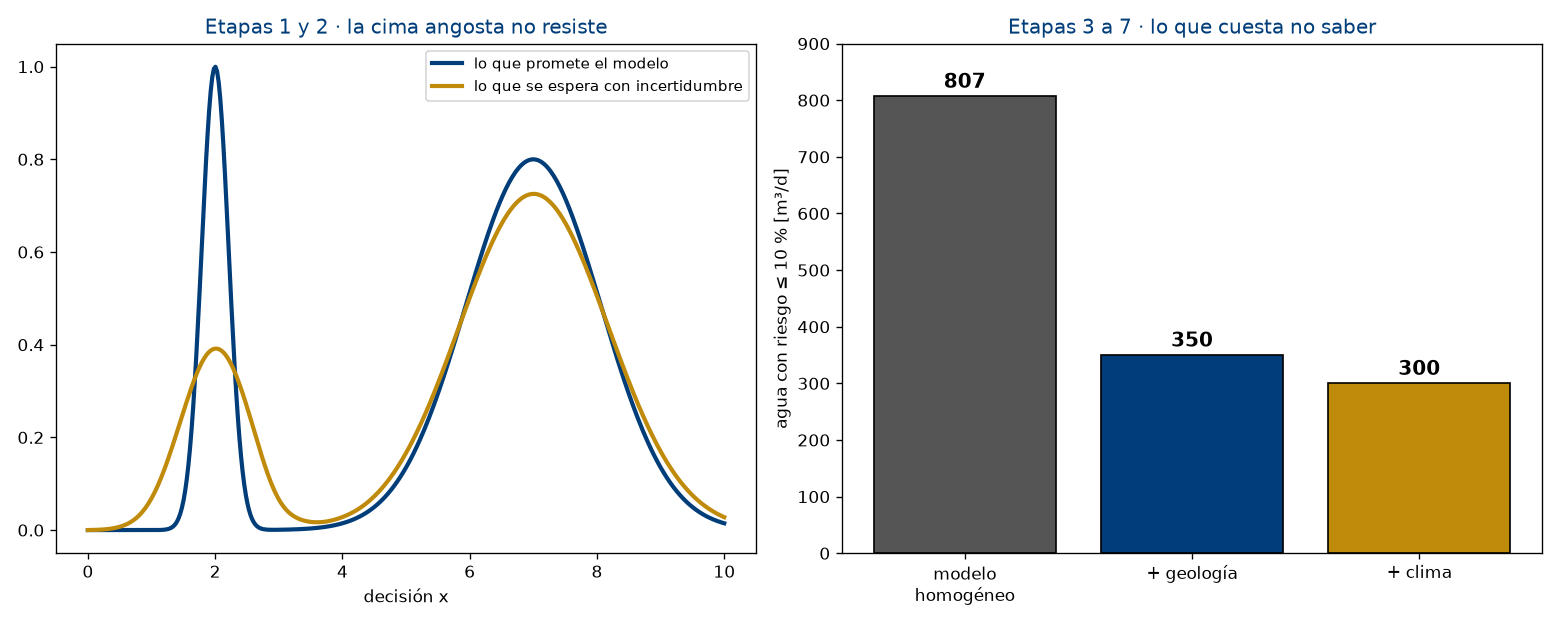

*Izquierda: con incertidumbre, la cima angosta deja de ser la mejor. Derecha: cada incertidumbre que se incluye cuesta agua (lo calcularás tú).*

In [ ]:
# Preparación (se ejecuta sola). La PRIMERA vez fabrica los dos ensambles de 200 geologías con el simulador: alrededor de un minuto.
# Si tarda mucho más, mira el último paso impreso y díselo al instructor.
import sys, os, glob
print("paso 1 de 5: localizando este cuaderno…", flush=True)
_ruta = os.path.abspath(globals().get("__vsc_ipynb_file__") or next(iter(sorted(glob.glob("Tarea_4*.ipynb"))), "Tarea_4.ipynb"))
print("          ", _ruta, flush=True)
for _modulo, _archivo in (("hidra", "hidra.py"), ("ParOMOPSO_det", os.path.join("pyOMOPSO", "ParOMOPSO_det.py"))):
    try:
        __import__(_modulo)
    except ImportError:
        for _inicio in (os.path.dirname(_ruta), os.getcwd()):
            _d = _inicio
            for _ in range(6):
                _c = next((c for c in (_d, os.path.join(_d, "Información", "codigo")) if os.path.exists(os.path.join(c, _archivo))), None)
                if _c:
                    sys.path.insert(0, os.path.dirname(os.path.join(_c, _archivo))); break
                _d = os.path.dirname(_d)
print("paso 2 de 5: cargando numpy y matplotlib…", flush=True)
import numpy as np
import matplotlib.pyplot as plt
print("paso 3 de 5: cargando hidra y OMOPSO, y los dos ensambles de 200 geologías…", flush=True)
import hidra
from ParOMOPSO_det import parOMOPSO_det as OMOPSO_correr
alpha0, alpha_h0 = hidra.matriz_respuesta(), hidra.coeficientes_humedal()
N_GEOLOGIAS = 200     # geologías de cada ensamble (las mismas para todos, por sus semillas). La tarea se entrega con 200;
                      # después puedes subirlo para explorar, como en el cuaderno de la sesión
OPT = hidra.ensamble(N_GEOLOGIAS, "optimizacion"); VAL = hidra.ensamble(N_GEOLOGIAS, "validacion")
A, H, A_val, H_val = OPT["alpha"], OPT["alpha_h"], VAL["alpha"], VAL["alpha_h"]
print("paso 4 de 5: cargando otter (las comprobaciones)…", flush=True)
import otter
print("paso 5 de 5: preparando el calificador…", flush=True)
grader = otter.Notebook(_ruta)

S_MAX, S_HUM, DEMANDA = 3.0, 1.25, 1200.0

def f(x):
    # la función de dos cimas de la sección 1 del cuaderno
    x = np.asarray(x, dtype=float)
    return np.exp(-((x - 2) / 0.3)**2) + 0.8 * np.exp(-((x - 7) / 1.5)**2)
Z_MUESTRAS = np.random.default_rng(0).normal(0, 1, 2000)       # z ~ N(0, 1): δ = σ z
XS = np.linspace(0, 10, 501)

_g = np.arange(0, 401, 10.0)
MALLA = np.array(np.meshgrid(_g, _g, _g, indexing="ij")).reshape(3, -1).T      # 68 921 decisiones, cada 10 m³/d
Z_MALLA = MALLA.sum(axis=1)

def fallas_malla(A, H, lim_pozo=None, lim_hum=None):
    # (decisiones, geologías): ¿rompe alguna regla cada decisión de la malla en cada geología? (los límites pueden cambiar por geología)
    n = len(A)
    lim_pozo = np.full(n, S_MAX) if lim_pozo is None else lim_pozo
    lim_hum = np.full(n, S_HUM) if lim_hum is None else lim_hum
    return np.stack([((MALLA @ A[k].T) > lim_pozo[k] + 1e-9).any(axis=1) | ((MALLA @ H[k]) > lim_hum[k] + 1e-9) for k in range(n)], axis=1)

def mejor_con_riesgo(R, r):
    # índice de la decisión de la malla con más agua y riesgo ≤ r
    ok = R <= r + 1e-12
    return int(np.flatnonzero(ok)[np.argmax(Z_MALLA[ok])])

def frente_riesgo(R):
    # el frente exacto (déficit, riesgo, índice en la malla): para cada riesgo, la decisión con más agua
    filas = []
    for r in np.unique(R):
        i = mejor_con_riesgo(R, r)
        if not filas or DEMANDA - Z_MALLA[i] < filas[-1][0] - 1e-9:
            filas.append([DEMANDA - Z_MALLA[i], R[i], i])
    return np.array(filas)

FALLAS = fallas_malla(A, H); FALLAS_VAL = fallas_malla(A_val, H_val)
R_opt, R_val = FALLAS.mean(axis=1), FALLAS_VAL.mean(axis=1)
print("Herramientas listas.")

## Etapa 0 · Tus datos (sin puntos)

Escribe el **mismo correo** de las tareas anteriores: identifica tu entrega. Esta tarea usa los mismos datos para todos.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Tu correo de inscripción, entre comillas. El mismo de las tareas anteriores.
IDENTIFICADOR = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Entrega de:", IDENTIFICADOR)

In [ ]:
grader.check("q0")

## Etapa 1 · Las dos cimas (1 punto)

**Problema.** La función de la sección 1 del cuaderno, `f`: una cima alta y angosta en $x = 2$ y una baja y ancha en $x = 7$. Lo que ocurre es $x + \delta$, con
$\delta = \sigma z$ y $z \sim \mathcal{N}(0, 1)$ (2 000 muestras en `Z_MUESTRAS`).

**Pregunta.**

1. Escribe la **esperanza por Monte Carlo**: `esperanza = lambda x, sigma: ...`, el promedio de `f(x + sigma * Z_MUESTRAS)`.
2. Ejecuta: la celda busca el óptimo robusto para seis valores de σ. Escribe `sigma_cambio`: el **menor** σ de la tabla en que el óptimo robusto ya es la
   cima ancha ($x^* > 5$).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# La esperanza de f(x + δ), con δ = sigma · z, por Monte Carlo. Sintaxis: lambda x, sigma: ...
esperanza = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
tabla_sigma = {}
fig, ax = plt.subplots(figsize=(9, 4.3))
ax.plot(XS, f(XS), color='k', lw=1, ls=':', label='f(x) sin incertidumbre')
print("  σ     óptimo robusto x*    E[f] en x*")
for s in (0.05, 0.10, 0.15, 0.20, 0.25, 0.30):
    E = np.array([esperanza(x, s) for x in XS]); tabla_sigma[s] = XS[np.argmax(E)]
    ax.plot(XS, E, lw=2, label=f'σ = {s}')
    print(f"{s:5.2f}        {tabla_sigma[s]:5.2f}           {E.max():.3f}")
ax.set_xlabel('x'); ax.set_ylabel('E[f(x + δ)]'); ax.legend(fontsize=8, ncol=2); ax.set_title('Tu esperanza con seis incertidumbres')
plt.tight_layout(); plt.show()

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El menor σ de la tabla con el óptimo robusto en la cima ancha (x* > 5)
sigma_cambio = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Desde σ =", sigma_cambio, "la cima ancha es la decisión robusta.")

In [ ]:
grader.check("q1")

## Etapa 2 · ¿Robusto según qué? (1 punto)

**Problema.** Con $\sigma = 0.5$, cada decisión $x$ da 2 000 valores posibles de $f(x + \delta)$ (sección 1.4, ejemplo 2 del cuaderno). Dos medidas de robustez:

- el **peor caso**: el percentil **10** de esos valores;
- la **fiabilidad**: la fracción de esos valores **mayores que 0.9**.

**Pregunta.** Escribe las dos medidas como funciones de un arreglo `v` de valores. La celda busca la mejor decisión con cada una.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El peor caso (percentil 10) y la fiabilidad (fracción mayor que 0.9) de un arreglo de valores v. Sintaxis: lambda v: ...
peor_caso = ...
fiabilidad = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
V = f(XS[:, None] + 0.5 * Z_MUESTRAS[None, :])             # (501 decisiones, 2 000 valores)
medidas = {'media': V.mean(axis=1), 'peor caso (percentil 10)': np.array([peor_caso(v) for v in V]),
           'fiabilidad P(f > 0.9)': np.array([fiabilidad(v) for v in V])}
x_por_medida = {nombre: XS[np.argmax(m)] for nombre, m in medidas.items()}
fig, ax = plt.subplots(figsize=(9, 4.3))
for nombre, m in medidas.items():
    ax.plot(XS, m, lw=2, label=f'{nombre}: mejor en x = {x_por_medida[nombre]:.1f}')
ax.set_xlabel('x'); ax.legend(); ax.set_title('Tus medidas de robustez (σ = 0.5)'); plt.tight_layout(); plt.show()

In [ ]:
grader.check("q2")

## Etapa 3 · ¿Qué tan en serio tomo el frente de la sesión 3? (1 punto)

**Problema.** El frente de **dos objetivos** de la sesión 3 (sección 2 de aquel cuaderno: costo del bombeo contra índice de necesidad no cubierta) se calculó
con el acuífero homogéneo. Es más sencillo que el de tres objetivos de la sección 2 del cuaderno de hoy, pero el riesgo se mide igual. La celda lo vuelve a
calcular con la malla. Para saber qué tan en serio tomarlo hay que medir el **riesgo** de cada decisión: la fracción de las 200 geologías en que rompe alguna
regla (algún pozo > 3 m o el humedal > 1.25 m).

**Pregunta.**

1. Escribe el riesgo de una decisión `x` (un arreglo de 3) con las matrices del ensamble `A` (200 × 3 × 3) y `H` (200 × 3), como en la sección 2.4 del cuaderno.
2. Escribe `fraccion_segura`: la fracción de las decisiones del frente con riesgo **≤ 5 %** (usa el arreglo `riesgos_frente`).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El riesgo de la decisión x en el ensamble. Sintaxis: lambda x: np.mean(...)
riesgo = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
C_QP = np.array([0.01, 0.015, 0.02]); GSLEV = 40.0; H0 = np.array([34.0, 34.0, 15.0])
C_BASE = np.array([2.0, 1.5, 0.8]); A_IDX = np.array([0.10, 0.20, 0.15]) / 10
S0 = MALLA @ alpha0.T
legal0 = (S0 <= S_MAX).all(axis=1) & (MALLA @ alpha_h0 <= S_HUM)
F0 = np.column_stack([(C_QP * MALLA * (GSLEV - H0 + S0)).sum(1), np.exp(-0.5 * (C_BASE + A_IDX * MALLA)).sum(1)])
idx = np.flatnonzero(legal0); orden = idx[np.lexsort((F0[idx, 1], F0[idx, 0]))]; frente3, mejor = [], np.inf
for i in orden:
    if F0[i, 1] < mejor:
        frente3.append(i); mejor = F0[i, 1]
X_frente3 = MALLA[frente3]
riesgos_frente = np.array([riesgo(x) for x in X_frente3])
fig, ax = plt.subplots(figsize=(8.5, 4.6))
sc = ax.scatter(F0[frente3, 0], F0[frente3, 1], c=riesgos_frente, cmap='RdYlGn_r', vmin=0, vmax=1, s=22, edgecolors='k', linewidths=0.3)
plt.colorbar(sc, label='riesgo en 200 geologías')
ax.set_xlabel('costo del bombeo [$/d]'); ax.set_ylabel('índice de necesidad no cubierta'); ax.set_title('El frente de la sesión 3, coloreado por su riesgo')
plt.tight_layout(); plt.show()
print(f"{len(X_frente3)} decisiones en el frente; riesgo de {riesgos_frente.min():.0%} a {riesgos_frente.max():.0%}")

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Fracción de las decisiones del frente con riesgo ≤ 5 % (con riesgos_frente)
fraccion_segura = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print(f"Solo {fraccion_segura:.0%} de las decisiones del frente fallan en 5 % de las geologías o menos.")

In [ ]:
grader.check("q3")

## Etapa 4 · ¿Cuánta agua, con qué riesgo? (1.5 puntos)

**Problema.** El problema robusto de la sección 3 del cuaderno: minimizar el déficit ($1200 - \sum p_i$) y el riesgo. La celda calcula el frente exacto con la
malla. Fritz acepta un riesgo de **10 %**.

**Pregunta.**

1. Escribe `agua_10`: el máximo bombeo con riesgo ≤ 10 %. Usa `Z_MALLA` y la función `mejor_con_riesgo(R_opt, r)`, que da el índice de esa decisión en la malla.
2. Elige `N_POP` y `MAX_ITER` para **OMOPSO robusto** (como mucho 4 000 movimientos: `N_POP * MAX_ITER`). La meta: que en promedio le falten **≤ 20 m³/d**
   frente al exacto.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El máximo bombeo con riesgo ≤ 10 % (con Z_MALLA y mejor_con_riesgo)
agua_10 = ...
# Partículas e iteraciones de OMOPSO robusto (producto ≤ 4 000)
N_POP = ...
MAX_ITER = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
FR = frente_riesgo(R_opt)
i_10 = mejor_con_riesgo(R_opt, 0.10)
print(f"riesgo ≤ 10 %: {agua_10:.0f} m³/d con p = {MALLA[i_10]}")

def objetivos_robustos(q):
    x = np.asarray(q, dtype=float)
    return np.array([[DEMANDA - x.sum(), np.mean(((A @ x) > S_MAX).any(axis=1) | ((H @ x) > S_HUM))]]).T
parametros = {'MaxIter': MAX_ITER, 'nPop': N_POP, 'w1': 0.1, 'w2': 0.5, 'e': 0.001, 'c1': 1.5, 'c2': 2, 'nGrid': 7, 'alpha': 0.1,
              'wdamp': 0.99, 'r1': 0, 'r2': 1, 'verbose': 0}
np.random.seed(2026)
e_rob, _, _ = OMOPSO_correr({'CostFunction': objetivos_robustos, 'nVar': 3, 'VarMin': 0, 'VarMax': 400}, parametros)
F_omo = np.array([np.ravel(s['cost']) for s in e_rob])
falta_media = float(np.mean([F_omo[F_omo[:, 1] <= r + 1e-12, 0].min() - d for d, r, _ in FR if (F_omo[:, 1] <= r + 1e-12).any()]))
print(f"OMOPSO robusto ({N_POP} × {MAX_ITER}): {len(F_omo)} soluciones; le faltan en promedio {falta_media:.1f} m³/d frente al exacto")
fig, ax = plt.subplots(figsize=(8.5, 4.8))
ax.step(DEMANDA - FR[:, 0], FR[:, 1], where='post', color='#003D79', lw=2.5, label='frente exacto (200 geologías)')
ax.plot(DEMANDA - F_omo[:, 0], F_omo[:, 1], 'o', mfc='#C08A0B', mec='k', ms=6, label='tu OMOPSO robusto')
ax.plot(agua_10, R_opt[i_10], '*', ms=20, mfc='#2d6a2d', mec='k', label=f'tu decisión con riesgo ≤ 10 % ({agua_10:.0f} m³/d)')
ax.set_xlabel('bombeo total [m³/d]'); ax.set_ylabel('riesgo'); ax.set_xlim(0, 1000); ax.legend(); ax.set_title('Tu menú agua contra riesgo')
plt.tight_layout(); plt.show()

In [ ]:
grader.check("q4")

## Etapa 5 · ¿Me puedo creer ese riesgo? (1 punto)

**Problema.** El riesgo de 10 % se calculó con las mismas 200 geologías con que se optimizó. Lo honesto es medirlo en las 200 de **validación** (sección 3.4).
Y si se optimiza con menos geologías, la promesa puede no cumplirse (también en la sección 3.4).

**Pregunta.**

1. Escribe `riesgo_real_10`: el riesgo de tu decisión `i_10` en el ensamble de validación (usa `R_val`).
2. La celda repite la decisión con riesgo ≤ 10 % usando solo las primeras N geologías. Escribe `n_minimo`: el **menor** N de la tabla cuyo riesgo real
   (en validación) es **≤ 15 %**.

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El riesgo real de la decisión i_10, en las 200 geologías de validación
riesgo_real_10 = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
tabla_n = {}
print("   N    bombeo   riesgo real (validación)")
for n in (10, 25, 50, 100, 200):
    i = mejor_con_riesgo(FALLAS[:, :n].mean(axis=1), 0.10); tabla_n[n] = (Z_MALLA[i], R_val[i])
    print(f"{n:4d}    {Z_MALLA[i]:5.0f}      {R_val[i]:6.1%}")
fig, ax = plt.subplots(figsize=(8, 4))
ax.plot(list(tabla_n), [v[1] for v in tabla_n.values()], 'o-', color='#C08A0B', lw=2, label='riesgo real')
ax.axhline(0.10, color='k', ls=':', label='lo que se pidió: 10 %'); ax.axhline(0.15, color='#B03A2E', ls='--', label='tolerancia: 15 %')
ax.set_xscale('log'); ax.set_xlabel('geologías con que se optimizó (N)'); ax.set_ylabel('riesgo real'); ax.legend(); ax.set_title('Tu prueba de fuego')
plt.tight_layout(); plt.show()
print(f"tu decisión de la etapa 4: prometía 10 %, en validación {riesgo_real_10:.1%}")

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# El menor N de la tabla con riesgo real ≤ 0.15
n_minimo = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print("Hacen falta al menos", n_minimo, "geologías para que la promesa sea creíble.")

In [ ]:
grader.check("q5")

## Etapa 6 · ¿Y si además cambia el clima? (1.5 puntos)

**Problema.** La sección 4 del cuaderno: cada geología del ensamble viene con un mes al azar. `estiaje` vale 1 en el mes más seco y 0 en el más húmedo. En
estiaje el nivel estático baja hasta 0.8 m (el abatimiento disponible en los pozos es $3 - 0.8\cdot\text{estiaje}$) y el humedal tolera menos
($1.25 - 0.20\cdot\text{estiaje}$).

**Pregunta.**

1. Escribe los dos límites con el clima, como arreglos de 200 (uno por geología), con `S_MAX`, `S_HUM` y `estiaje`.
2. Escribe `costo_clima`: cuántos m³/d menos se pueden bombear con riesgo ≤ 10 % cuando se incluye el clima (usa `agua_10` y `agua_10_clima`).
3. Escribe `riesgo_ignorado`: el riesgo de tu decisión `i_10` (la de la etapa 4, robusta solo a la geología) cuando el clima existe (usa `FALLAS_CLIMA`).

In [ ]:
mes = np.random.default_rng(7).integers(0, 12, len(A))
estiaje = 0.5 * (1 + np.cos(2 * np.pi * mes / 12))
print("meses de las primeras diez geologías:", mes[:10], "| estiaje:", np.round(estiaje[:10], 2))

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Los límites con el clima: abatimiento disponible en los pozos y tolerancia del humedal (arreglos de 200)
lim_pozo_clima = ...
lim_hum_clima = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
FALLAS_CLIMA = fallas_malla(A, H, lim_pozo=lim_pozo_clima, lim_hum=lim_hum_clima)
R_clima = FALLAS_CLIMA.mean(axis=1)
agua_10_clima = Z_MALLA[mejor_con_riesgo(R_clima, 0.10)]
FR_clima = frente_riesgo(R_clima)
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(14, 4.6))
ax1.step(DEMANDA - FR[:, 0], FR[:, 1], where='post', color='#003D79', lw=2.2, label='geología')
ax1.step(DEMANDA - FR_clima[:, 0], FR_clima[:, 1], where='post', color='#C08A0B', lw=2.2, label='geología + clima')
ax1.axhline(0.10, color='k', ls=':'); ax1.set_xlim(0, 900); ax1.set_ylim(0, 0.5)
ax1.set_xlabel('bombeo total [m³/d]'); ax1.set_ylabel('riesgo'); ax1.legend(); ax1.set_title('El clima corre el frente')
ax2.bar(['modelo homogéneo', '+ geología', '+ clima'], [807, agua_10, agua_10_clima], color=['#555555', '#003D79', '#C08A0B'], edgecolor='k')
ax2.set_ylabel('agua con riesgo ≤ 10 % [m³/d]'); ax2.set_title('Tu escalera del costo de la robustez')
plt.tight_layout(); plt.show()
print(f"con riesgo ≤ 10 %: {agua_10:.0f} m³/d con la geología, {agua_10_clima:.0f} con geología y clima")

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Lo que cuesta el clima con riesgo ≤ 10 % y el riesgo real de i_10 cuando existe el clima
costo_clima = ...
riesgo_ignorado = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print(f"el clima cuesta {costo_clima:.0f} m³/d; la decisión robusta solo a la geología prometía 10 % y con el clima falla en {riesgo_ignorado:.1%}")

In [ ]:
grader.check("q6")

## Etapa 7 · ¿Vale la pena medir antes de decidir? (1 punto)

**Problema.** En el cuaderno (sección 4.3) la prueba de bombeo fue en el pozo 1. Fritz pregunta por una prueba en el **pozo 2**: se bombea solo el pozo 2 y se
mide cuánto abaten los tres pozos y el humedal. Eso es la **columna 2** de la matriz de la geología (índice 1 en Python) y el **elemento 2** de la fila del
humedal. Con las 80 geologías del ensamble más parecidas a lo medido se vuelve a decidir, pidiendo 2.5 % de riesgo.

**Pregunta.**

1. Escribe `observar(al, ah)`: lo que mide la prueba en una geología con matriz `al` (3 × 3) y fila del humedal `ah` (3): un arreglo de 4 números.
2. Escribe `ganancia`: cuánta agua de más se decide bombear **en promedio** con la prueba (usa `agua_con_prueba`, un arreglo, y `agua_sin_prueba`).

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Lo que mide la prueba en el pozo 2: la columna de índice 1 de la matriz y el elemento de índice 1 del humedal. Sintaxis: lambda al, ah: np.append(...)
observar = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
obs_ens = np.array([observar(A[k], H[k]) for k in range(len(A))])
escala = obs_ens.std(axis=0)
i_5 = mejor_con_riesgo(R_opt, 0.05); agua_sin_prueba = Z_MALLA[i_5]
agua_con_prueba, falla_con_prueba = [], []
for v in range(len(A_val)):
    cercanas = np.argsort(np.linalg.norm((obs_ens - observar(A_val[v], H_val[v])) / escala, axis=1))[:80]
    i = mejor_con_riesgo(FALLAS[:, cercanas].mean(axis=1), 0.025)
    agua_con_prueba.append(Z_MALLA[i]); falla_con_prueba.append(FALLAS_VAL[i, v])
agua_con_prueba = np.array(agua_con_prueba)
fig, ax = plt.subplots(figsize=(8, 4.2))
ax.hist(agua_con_prueba, bins=20, color='#8fd18f', edgecolor='k', label='con la prueba en el pozo 2')
ax.axvline(agua_sin_prueba, color='#003D79', lw=2.5, label=f'sin prueba: {agua_sin_prueba:.0f} m³/d')
ax.axvline(agua_con_prueba.mean(), color='#C08A0B', lw=2.5, ls='--', label=f'con prueba, en promedio: {agua_con_prueba.mean():.0f} m³/d')
ax.set_xlabel('agua que se decide bombear [m³/d]'); ax.set_ylabel('casos (200 geologías reales)'); ax.legend(fontsize=9)
ax.set_title('El valor de tu prueba de bombeo'); plt.tight_layout(); plt.show()
print(f"falla real: sin prueba {R_val[i_5]:.1%}, con prueba {np.mean(falla_con_prueba):.1%}")

In [ ]:
# ╔════════════════════════════════════════════════════════════╗
# ║   INGRESA AQUÍ LOS DATOS SOLICITADOS (sustituye los ...)   ║
# ╚════════════════════════════════════════════════════════════╝
# Cuánta agua de más se decide en promedio con la prueba
ganancia = ...

# ──────────────────────────────────────────────────────────────
#   NO MODIFIQUES DE AQUÍ EN ADELANTE: esta parte se ejecuta sola
# ──────────────────────────────────────────────────────────────
print(f"la prueba en el pozo 2 vale, en promedio, {ganancia:.0f} m³/d")

In [ ]:
grader.check("q7")

## Etapa 8 · El informe final (2 puntos, los leo yo)

Responde en las celdas de texto, entre tres y cinco líneas cada una, con **tus** números.

<!-- BEGIN QUESTION -->

**8a.** Con tus etapas 1 a 3: ¿por qué la decisión «óptima» no es necesariamente la robusta, y por qué la medida de robustez es una decisión? ¿Qué te dice la fracción segura del frente de la sesión 3?

<!-- RESPUESTA:q8a -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**8b.** Fritz pregunta: «¿me puedo creer el 10 % de riesgo?». Contéstale con tus etapas 4 y 5: riesgo prometido y real, y qué pasa si se optimiza con pocas geologías.

<!-- RESPUESTA:q8b -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

<!-- BEGIN QUESTION -->

**8c.** Con tus etapas 6 y 7: ¿cuánto cuesta el clima, qué pasa si se ignora, y vale la pena la prueba de bombeo en el pozo 2? ¿Qué le recomiendas a Fritz?

<!-- RESPUESTA:q8c -->
_Escribe tu respuesta aquí, en esta misma celda, debajo de esta línea._

<!-- END QUESTION -->

---
### Antes de entregar

1. Menú **Ejecutar todo** (Run All): el cuaderno debe correr de principio a fin sin errores. Tarda unos dos minutos (más la primera vez, mientras se fabrican los ensambles).
2. Revisa que cada `grader.check` muestre sus pruebas visibles en verde.
3. Guarda el archivo como `Tarea_4_<tu nombre>.ipynb` y súbelo al formulario del curso a más tardar el **viernes 27 de noviembre**.